# 02 · EDA and stationarity diagnostics (Z1–Z3)

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller, kpss

pd.set_option("display.max_columns", 20)

In [2]:
ROOT = Path.cwd().resolve()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
if not (ROOT / "requirements.txt").exists():
    raise FileNotFoundError("Start Jupyter from the project root or notebooks/ folder.")

FEATURES_PATH = ROOT / "data/processed/z1_z3_monthly.csv"
LEVELS_PATH = ROOT / "data/interim/z1_z3_levels_monthly.csv"
FIG_DIR = ROOT / "reports/figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

if not FEATURES_PATH.exists() or not LEVELS_PATH.exists():
    raise FileNotFoundError("Run notebook 01 first; this notebook needs its two CSV outputs.")

Load and inspect the two monthly datasets

In [3]:
data = pd.read_csv(FEATURES_PATH, parse_dates=["date"], index_col="date")
levels = pd.read_csv(LEVELS_PATH, parse_dates=["date"], index_col="date")
data = data.sort_index()
levels = levels.sort_index()

assert data.index.is_unique, "Feature dates should be unique"
assert levels.index.is_unique, "Level dates should be unique"

print("Data shape:", data.shape)
print("Date range:", data.index.min().date(), "to", data.index.max().date())
display(data.head())

Data shape: (202, 3)
Date range: 2010-01-01 to 2026-10-01


,z1_yield_curve,z2_credit_spread,z3_unemployment_change
date,,,
2010-01-01,2.804211,0.99,-0.1
2010-02-01,2.834211,0.99,0.0
2010-03-01,2.768696,1.00,0.1
2010-04-01,2.786364,0.96,0.0
2010-05-01,2.589500,1.09,-0.3


Check missing observations and basic descriptive statistics

In [4]:
missing = pd.DataFrame({
    "missing_months": data.isna().sum(),
    "percent_missing": (100 * data.isna().mean()).round(2),
})
display(missing)
display(data.describe().T.round(3))

,missing_months,percent_missing
z1_yield_curve,0,0.00
z2_credit_spread,0,0.00
z3_unemployment_change,2,0.99


,count,mean,std,min,25%,50%,75%,max
z1_yield_curve,202.0,0.961,0.935,-0.929,0.258,0.838,1.655,2.834
z2_credit_spread,202.0,0.909,0.247,0.430,0.700,0.900,1.068,1.700
z3_unemployment_change,200.0,-0.029,0.795,-2.200,-0.100,0.000,0.025,10.400


Define the training and test periods

In [5]:
TRAIN_END = "2020-12-01"
TRAIN_START = "2010-01-01"
train = data.loc[TRAIN_START:TRAIN_END].copy()
test = data.loc["2021-01-01":].copy()

print("Training months:", len(train))
print("Testing months:", len(test))
print("Complete training rows:", len(train.dropna()))

Training months: 132
Testing months: 70
Complete training rows: 132


Inspect each series over time

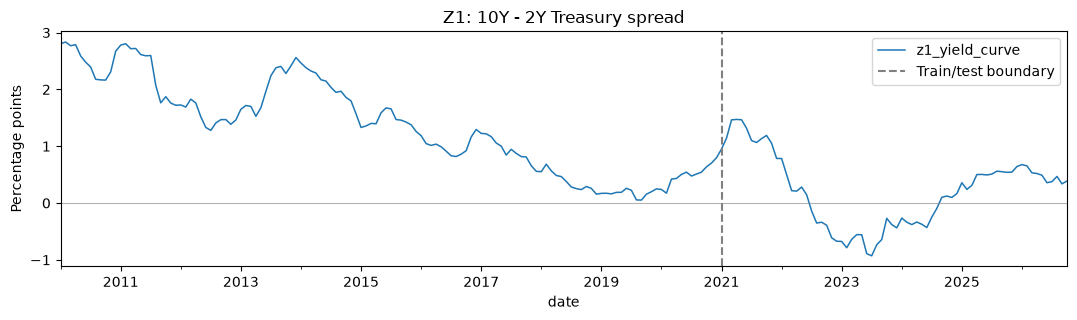

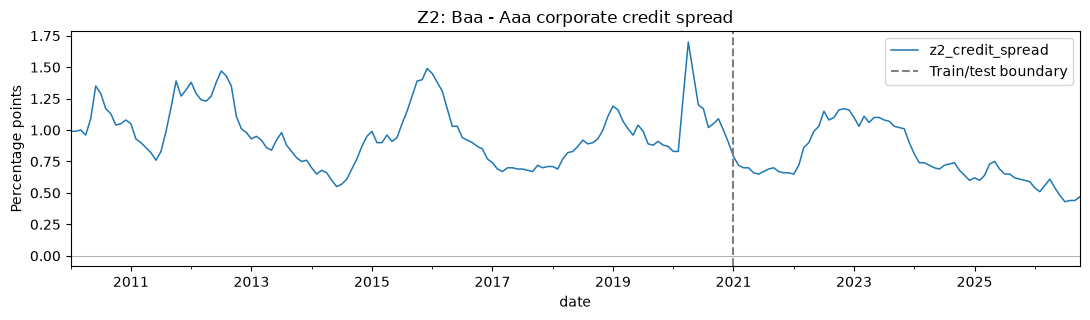

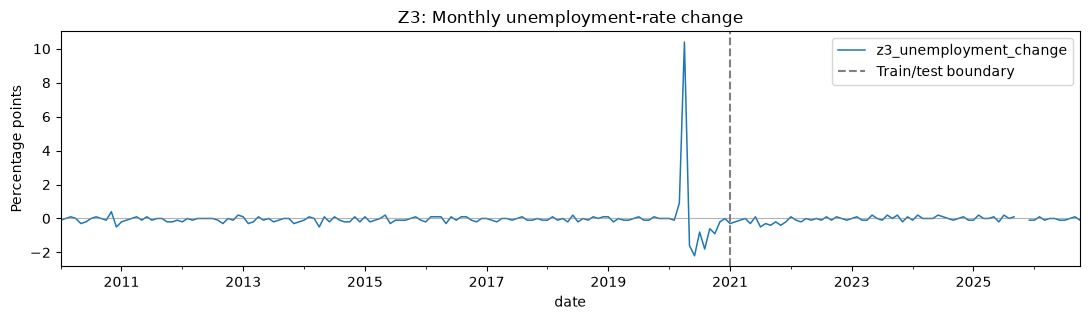

In [6]:
titles = {
    "z1_yield_curve": "Z1: 10Y - 2Y Treasury spread",
    "z2_credit_spread": "Z2: Baa - Aaa corporate credit spread",
    "z3_unemployment_change": "Z3: Monthly unemployment-rate change",
}

for column, title in titles.items():
    fig, ax = plt.subplots(figsize=(11, 3.3))
    data[column].plot(ax=ax, linewidth=1.1)
    ax.axvline(pd.Timestamp("2021-01-01"), linestyle="--", color="gray",
               label="Train/test boundary")
    ax.axhline(0, linewidth=0.8, color="gray", alpha=0.6)
    ax.set_title(title)
    ax.set_ylabel("Percentage points")
    ax.legend(loc="upper right")
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"{column}_time_series.png", dpi=150)
    plt.show()

Look at the training-sample distributions

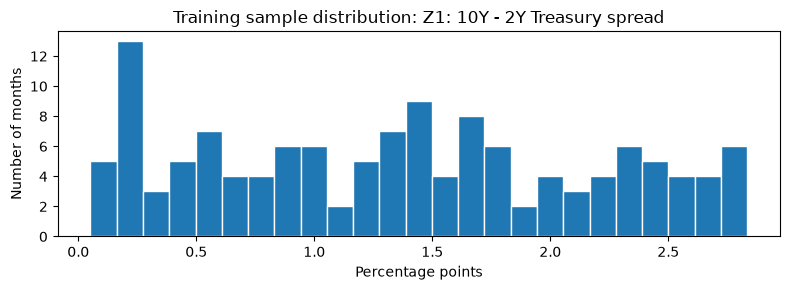

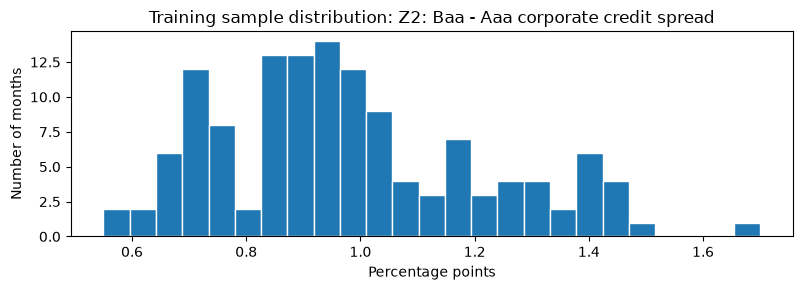

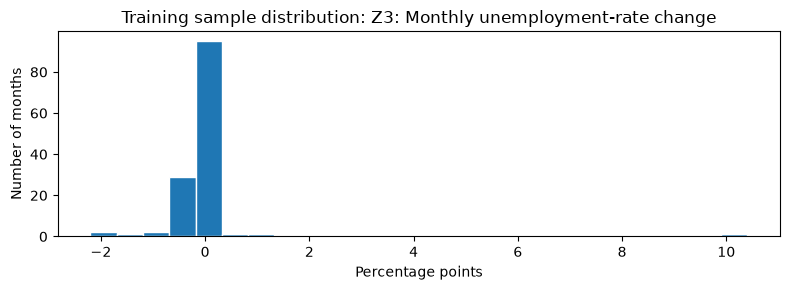

In [7]:
for column, title in titles.items():
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.hist(train[column].dropna(), bins=25, edgecolor="white")
    ax.set_title(f"Training sample distribution: {title}")
    ax.set_xlabel("Percentage points")
    ax.set_ylabel("Number of months")
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"{column}_histogram.png", dpi=150)
    plt.show()

Correlations among your three explanatory variables

,z1_yield_curve,z2_credit_spread,z3_unemployment_change
z1_yield_curve,1.000,-0.058,-0.061
z2_credit_spread,-0.058,1.000,0.209
z3_unemployment_change,-0.061,0.209,1.000


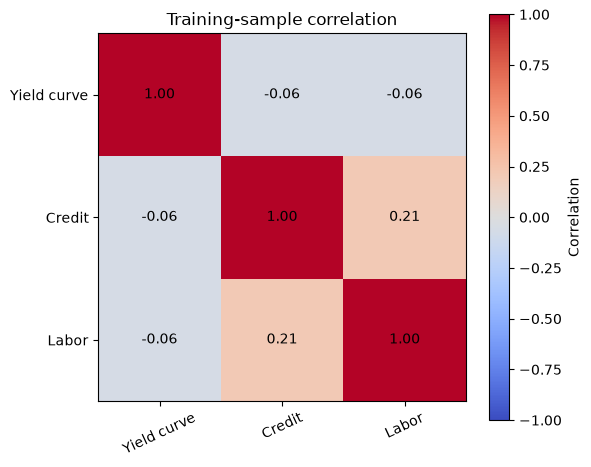

In [8]:
corr = train.corr()
display(corr.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr.columns)), ["Yield curve", "Credit", "Labor"], rotation=25)
ax.set_yticks(range(len(corr.index)), ["Yield curve", "Credit", "Labor"])
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Training-sample correlation")
plt.tight_layout()
fig.savefig(FIG_DIR / "training_correlations.png", dpi=150)
plt.show()

Define a small reusable stationarity-test function

In [9]:
def stationarity_tests(values, name):
    x = pd.to_numeric(values, errors="coerce").dropna()
    if len(x) < 30:
        raise ValueError(f"{name}: need at least 30 observations; got {len(x)}")

    adf_stat, adf_p, adf_lags, adf_nobs, *_ = adfuller(
        x, regression="c", autolag="AIC"
    )
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        kpss_stat, kpss_p, kpss_lags, *_ = kpss(
            x, regression="c", nlags="auto"
        )
    if caught:
        print(f"{name}: KPSS p-value may be at a table boundary.")

    adf_reject = adf_p < 0.05
    kpss_reject = kpss_p < 0.05
    if adf_reject and not kpss_reject:
        reading = "Both tests consistent with level stationarity"
    elif not adf_reject and kpss_reject:
        reading = "Both tests suggest nonstationarity"
    else:
        reading = "Mixed / inconclusive; inspect the time plot"

    return {
        "variable": name,
        "observations": len(x),
        "adf_statistic": adf_stat,
        "adf_pvalue": adf_p,
        "adf_lags": adf_lags,
        "kpss_statistic": kpss_stat,
        "kpss_pvalue": kpss_p,
        "kpss_lags": kpss_lags,
        "interpretation": reading,
    }

Run ADF and KPSS on Z1, Z2, and Z3

In [10]:
results = pd.DataFrame([
    stationarity_tests(train[column], column)
    for column in train.columns
]).set_index("variable")

display(results.round(4))

z1_yield_curve: KPSS p-value may be at a table boundary.
z2_credit_spread: KPSS p-value may be at a table boundary.
z3_unemployment_change: KPSS p-value may be at a table boundary.


/var/folders/0v/rd7dv3r524n7kh9f6fqcc0sc0000gn/T/ipykernel_22381/4124442540.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, adf_nobs, *_ = adfuller(
/var/folders/0v/rd7dv3r524n7kh9f6fqcc0sc0000gn/T/ipykernel_22381/4124442540.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, adf_nobs, *_ = adfuller(
/var/folders/0

,observations,adf_statistic,adf_pvalue,adf_lags,kpss_statistic,kpss_pvalue,kpss_lags,interpretation
variable,,,,,,,,
z1_yield_curve,132,-1.6531,0.4554,5,1.6977,0.01,6,Both tests suggest nonstationarity
z2_credit_spread,132,-3.3324,0.0135,5,0.1604,0.10,6,Both tests consistent with level stationarity
z3_unemployment_change,132,-9.1771,0.0000,1,0.0754,0.10,4,Both tests consistent with level stationarity


Check unemployment level versus unemployment change

We use `UNRATE.diff()` as Z3 because the project specifies **a monthly change**, not unemployment in levels. Comparing the two helps illustrate why differencing changes the time-series behavior; the test outcomes do not determine economic usefulness.

In [11]:
unemployment_level = levels.loc[TRAIN_START:TRAIN_END, "UNRATE"].dropna()
unemployment_change = train["z3_unemployment_change"].dropna()

comparison = pd.DataFrame([
    stationarity_tests(unemployment_level, "UNRATE level"),
    stationarity_tests(unemployment_change, "UNRATE monthly change"),
]).set_index("variable")
display(comparison.round(4))

UNRATE level: KPSS p-value may be at a table boundary.
UNRATE monthly change: KPSS p-value may be at a table boundary.


/var/folders/0v/rd7dv3r524n7kh9f6fqcc0sc0000gn/T/ipykernel_22381/4124442540.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, adf_nobs, *_ = adfuller(
/var/folders/0v/rd7dv3r524n7kh9f6fqcc0sc0000gn/T/ipykernel_22381/4124442540.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, adf_nobs, *_ = adfuller(


,observations,adf_statistic,adf_pvalue,adf_lags,kpss_statistic,kpss_pvalue,kpss_lags,interpretation
variable,,,,,,,,
UNRATE level,132,-2.7101,0.0723,0,1.1284,0.01,6,Both tests suggest nonstationarity
UNRATE monthly change,132,-9.1771,0.0000,1,0.0754,0.10,4,Both tests consistent with level stationarity


Inspect serial dependence with ACF plots

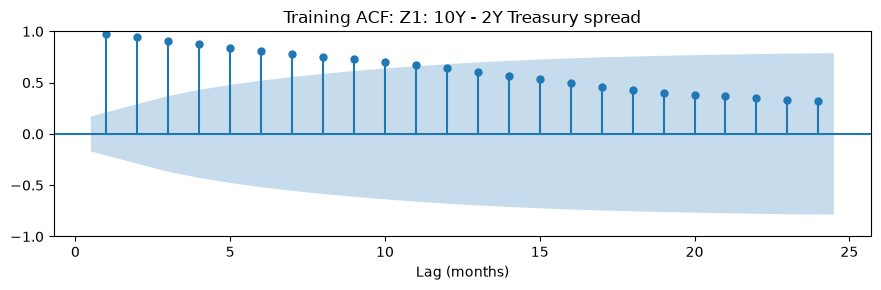

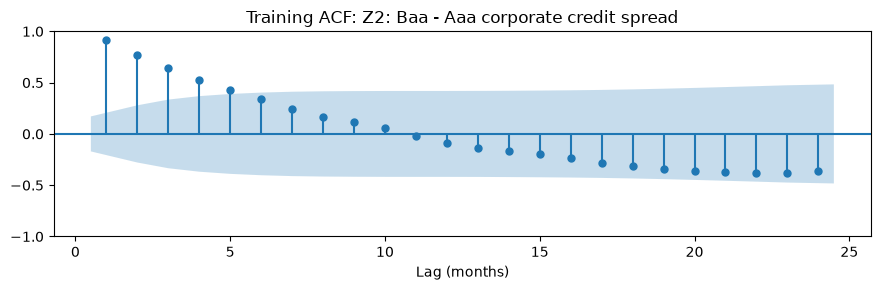

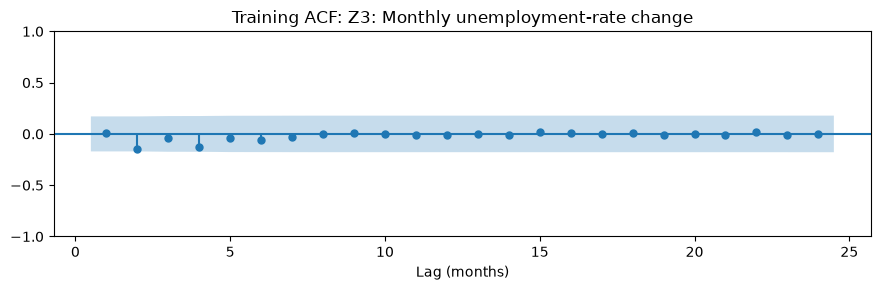

In [12]:
for column, title in titles.items():
    x = train[column].dropna()
    fig, ax = plt.subplots(figsize=(9, 3))
    plot_acf(x, lags=min(24, len(x) // 2 - 1), ax=ax, zero=False)
    ax.set_title(f"Training ACF: {title}")
    ax.set_xlabel("Lag (months)")
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"{column}_acf.png", dpi=150)
    plt.show()

Export compact descriptive and stationarity tables

In [13]:
summary = train.describe().T
summary["missing_months"] = train.isna().sum()

summary_path = ROOT / "reports" / "eda_descriptive_train.csv"
tests_path = ROOT / "reports" / "stationarity_results_train.csv"
summary.to_csv(summary_path)
results.to_csv(tests_path)

print("Saved:", summary_path.relative_to(ROOT))
print("Saved:", tests_path.relative_to(ROOT))
print("Figures saved in:", FIG_DIR.relative_to(ROOT))

Saved: reports/eda_descriptive_train.csv
Saved: reports/stationarity_results_train.csv
Figures saved in: reports/figures
